# AML 04 — Coordinate Regression

**Objective.** Predict `LONGITUDE` and `LATITUDE` from Wi-Fi signal-strength features using a Random Forest regressor, with the canonical preprocessing pipeline, feature definitions, and shared data split.

## Coordinate reference system and units

The CSV retains the dataset target names `LONGITUDE` and `LATITUDE`, but these
values are projected coordinates rather than degree-valued geographic longitude
and latitude. The supplied values (approximately x = -7,700 and y = 4,864,800)
match the coordinate scale and ranges reported for UJIIndoorLoc. A published
UJIIndoorLoc study identifies the coordinates as Web/Pseudo-Mercator
(EPSG:3857); the original UCI variable table provides the ranges but does not
state a CRS. Some related literature refers to UTM/WGS 84, but the supplied
negative x values around -7,700 do not match conventional UTM easting values.
Because the observed coordinate magnitudes align with EPSG:3857, we adopt
**EPSG:3857 projected metres** as the project convention and preserve the supplied
coordinates without reprojection.

All per-axis MAE and Euclidean errors below are in EPSG:3857 projected metres.
The Euclidean metric is planar distance in the projected coordinate grid; it is
not corrected for Web Mercator's latitude-dependent scale and should not be
interpreted as scale-corrected ground distance. The spatial plots use projected
coordinate axes directly and do not use a basemap.

Sources: [UCI UJIIndoorLoc dataset description](https://archive.ics.uci.edu/dataset/310/ujiindoorloc)
for the supplied variable ranges; [study identifying the UJIIndoorLoc coordinates
as EPSG:3857](https://pmc.ncbi.nlm.nih.gov/articles/PMC11478429/).

**Project:** Project 9 — Indoor Location Prediction Using Wi-Fi Signals  
**Phase:** AML (Phase 1)  
**Pipeline:** Coordinate Regression

## Notebook navigation

- [Coordinate reference system and units](#----)
- [1. Environment and configuration](#---)
- [2. Load data and validate schemas](#-----)
- [3. Prepare predictor matrices, targets, and identifiers](#------)
- [4. Baseline Random Forest regressor](#----)
- [5. Hyperparameter tuning](#--)
- [6. Freeze model configuration](#---)
- [7. Final held-out evaluation](#----)
- [8. Actual-versus-predicted plots](#----)
- [9. Coordinate-space error visualisations](#----)
- [10. Export CSV artifacts](#---)
- [11. Verification and summary](#---)
- [Conclusion](#)
- [Next Steps](#-)


## 1. Environment and configuration

Imports, reproducibility settings, and repository-relative paths are initialized in the code cells below. This notebook is designed to run independently from a fresh kernel.


**Cell purpose:** Imports dependencies and records the runtime and reproducibility settings.


In [1]:
# ── 0. Imports, versions, and reproducibility ─────────────────────────
from pathlib import Path
import platform
import re
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.multioutput import MultiOutputRegressor

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print(f"Python : {platform.python_version()} ({sys.executable})")
print(f"NumPy  : {np.__version__}")
print(f"pandas : {pd.__version__}")
print(f"sklearn: {__import__('sklearn').__version__}")
print(f"seaborn: {sns.__version__}")
print(f"matplotlib: {plt.matplotlib.__version__}")

Python : 3.14.2 (/Users/Krishiv/Desktop/Signal2Space/.venv/bin/python)
NumPy  : 2.5.4
pandas : 3.0.6
sklearn: 1.9.1
seaborn: 0.13.2
matplotlib: 3.11.2


**Cell purpose:** Locates the repository and defines the canonical input and output directories.


In [2]:
# ── 1. Locate repository root ─────────────────────────────────────────

def find_project_root(start=None):
    """Walk up from *start* (default: cwd) until the repo markers are found."""
    candidate = Path.cwd() if start is None else Path(start)
    for parent in (candidate, *candidate.parents):
        if (
            (parent / "data/raw/trainingData.csv").is_file()
            and (parent / "Machine Learning Pipeline").is_dir()
        ):
            return parent
    raise FileNotFoundError(
        "Could not locate the Signal2Space repository root "
        "from the current working directory."
    )

PROJECT_ROOT = find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
TABLES_DIR = PROJECT_ROOT / "data" / "tables"
FIGURES_DIR = PROJECT_ROOT / "data" / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = PROCESSED_DIR / "aml_internal_train_features.csv"
IVAL_PATH  = PROCESSED_DIR / "aml_internal_validation_features.csv"
HELDOUT_PATH = PROCESSED_DIR / "aml_heldout_validation_features.csv"

for p in (TRAIN_PATH, IVAL_PATH, HELDOUT_PATH):
    assert p.is_file(), f"Missing required input: {p}"

print(f"Project root : {PROJECT_ROOT}")
print(f"Processed feature dir: {PROCESSED_DIR}")
print(f"Model result tables dir: {TABLES_DIR}")

Project root : /Users/Krishiv/Desktop/Signal2Space
Processed feature dir: /Users/Krishiv/Desktop/Signal2Space/data/processed
Model result tables dir: /Users/Krishiv/Desktop/Signal2Space/data/tables


## 2. Load data and validate schemas

**Cell purpose:** Loads canonical internal-training and internal-validation feature tables.


In [3]:
# ── 1a. Read only the internal development splits ─────────────────────
# The held-out CSV is intentionally not opened until after model selection.
train_df = pd.read_csv(TRAIN_PATH)
ival_df  = pd.read_csv(IVAL_PATH)

print(f"Internal train      : {train_df.shape}")
print(f"Internal validation : {ival_df.shape}")


Internal train      : (16085, 1057)
Internal validation : (3852, 1057)


**Cell purpose:** Reconstructs feature columns and validates inputs, targets, and row keys.


In [4]:
# ── 1b. Reconstruct canonical feature column lists and validate development data ─

# Discover WAP columns from the verified training header
all_columns = train_df.columns.tolist()
AP_COLUMNS = sorted(
    [c for c in all_columns if re.fullmatch(r"RSSI_Z__WAP\d+", c)],
    key=lambda c: int(re.search(r"\d+", c.split("WAP")[1]).group()),
)
SEEN_COLUMNS = [c.replace("RSSI_Z__", "SEEN__") for c in AP_COLUMNS]
SUMMARY_COLUMNS = ["n_heard", "max_rssi_dbm", "mean_rssi_dbm",
                   "std_rssi_dbm", "n_strong", "top1_ap_index"]

FEATURE_COLUMNS = AP_COLUMNS + SEEN_COLUMNS + SUMMARY_COLUMNS

TARGET_COLUMNS = ["LONGITUDE", "LATITUDE"]
ALL_TARGET_COLUMNS = ["BUILDINGID", "FLOOR", "LONGITUDE", "LATITUDE"]
METADATA_COLUMNS = ["ROW_ID", "SOURCE_PARTITION", "SPACEID",
                    "RELATIVEPOSITION", "USERID", "PHONEID", "TIMESTAMP"]

# Validate only the internal development splits before tuning.
for name, df in [("train", train_df), ("ival", ival_df)]:
    missing_feat = [c for c in FEATURE_COLUMNS if c not in df.columns]
    missing_tgt  = [c for c in TARGET_COLUMNS if c not in df.columns]
    missing_meta = [c for c in METADATA_COLUMNS if c not in df.columns]
    assert not missing_feat, f"{name}: missing features {missing_feat}"
    assert not missing_tgt, f"{name}: missing targets {missing_tgt}"
    assert not missing_meta, f"{name}: missing metadata {missing_meta}"

assert train_df.columns.tolist() == ival_df.columns.tolist(), (
    "Column mismatch between internal train and validation"
)

print(f"WAP feature pairs : {len(AP_COLUMNS)} (RSSI_Z + SEEN = {2 * len(AP_COLUMNS)})")
print(f"Summary features  : {len(SUMMARY_COLUMNS)}")
print(f"Total predictors  : {len(FEATURE_COLUMNS)}")
print(f"Targets           : {TARGET_COLUMNS}")


WAP feature pairs : 520 (RSSI_Z + SEEN = 1040)
Summary features  : 6
Total predictors  : 1046
Targets           : ['LONGITUDE', 'LATITUDE']


## 3. Prepare predictor matrices, targets, and identifiers

Only `FEATURE_COLUMNS` are used as predictors. All targets (`BUILDINGID`,
`FLOOR`, `LONGITUDE`, `LATITUDE`) and metadata/identifiers are excluded from
the predictor matrix. Identifiers are retained separately for traceability.

**Cell purpose:** Separates predictors, coordinate targets, and identifiers.


In [5]:
# ── 2. Separate internal development features, targets, and identifiers ─

X_train = train_df[FEATURE_COLUMNS].values
y_train = train_df[TARGET_COLUMNS].values  # shape (n, 2): [LONGITUDE, LATITUDE]

X_ival = ival_df[FEATURE_COLUMNS].values
y_ival = ival_df[TARGET_COLUMNS].values
ival_ids = ival_df[["ROW_ID", "SOURCE_PARTITION"]].copy()

# ── Sanity checks ─────────────────────────────────────────────────────
forbidden = set(ALL_TARGET_COLUMNS + METADATA_COLUMNS)
used_features = set(FEATURE_COLUMNS)
assert not (used_features & forbidden), \
    f"Leakage: {used_features & forbidden} in predictors"

for label, arr in [("X_train", X_train), ("X_ival", X_ival),
                   ("y_train", y_train), ("y_ival", y_ival)]:
    assert np.isfinite(arr).all(), f"{label} has non-finite values"

print("Predictor / target shapes:")
print(f"  Train : X={X_train.shape}, y={y_train.shape}")
print(f"  IVal  : X={X_ival.shape},  y={y_ival.shape}")

# Coordinate ranges are descriptive of the development data only.
for i, col in enumerate(TARGET_COLUMNS):
    values = np.concatenate([y_train[:, i], y_ival[:, i]])
    print(f"  {col}: [{values.min():.2f}, {values.max():.2f}] EPSG:3857 projected metres")


Predictor / target shapes:
  Train : X=(16085, 1046), y=(16085, 2)
  IVal  : X=(3852, 1046),  y=(3852, 2)
  LONGITUDE: [-7691.34, -7300.82] EPSG:3857 projected metres
  LATITUDE: [4864745.75, 4865016.69] EPSG:3857 projected metres


## 4. Baseline Random Forest regressor

**Model family.** `RandomForestRegressor` from scikit-learn is chosen for its
native multi-output support (predicting both LONGITUDE and LATITUDE jointly),
robustness to feature scale, and interpretability. scikit-learn's
`RandomForestRegressor` supports multi-output natively by building each tree
to predict both targets simultaneously, so no `MultiOutputRegressor` wrapper
is needed.

**Baseline configuration.** 100 trees, no depth limit, `min_samples_leaf=1`,
`random_state=42`.

**Cell purpose:** Fits the baseline multi-output random forest regressor.


In [6]:
# ── 3. Baseline model ─────────────────────────────────────────────────

baseline_rf = RandomForestRegressor(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

baseline_rf.fit(X_train, y_train)
print("Baseline Random Forest fitted.")

y_ival_pred_base = baseline_rf.predict(X_ival)


def compute_metrics(y_true, y_pred, target_names=TARGET_COLUMNS):
    """Compute per-axis MAE and mean Euclidean distance.

    Returns
    -------
    dict with keys:
      - 'mae_<col>' : Mean Absolute Error for each target column (EPSG:3857 projected metres)
      - 'mean_euclidean_error' : Mean of sqrt((Δlon)² + (Δlat)²)  (EPSG:3857 projected metres)
      - 'median_euclidean_error' : Median Euclidean distance (EPSG:3857 projected metres)
      - 'p75_euclidean_error' : 75th percentile Euclidean distance (EPSG:3857 projected metres)
      - 'p95_euclidean_error' : 95th percentile Euclidean distance (EPSG:3857 projected metres)
    """
    result = {}
    for i, col in enumerate(target_names):
        result[f"mae_{col}"] = mean_absolute_error(y_true[:, i], y_pred[:, i])
    # Euclidean distance between actual and predicted 2D positions
    euclidean = np.sqrt(np.sum((y_true - y_pred) ** 2, axis=1))
    result["mean_euclidean_error"] = euclidean.mean()
    result["median_euclidean_error"] = np.median(euclidean)
    result["p75_euclidean_error"] = np.percentile(euclidean, 75)
    result["p95_euclidean_error"] = np.percentile(euclidean, 95)
    return result


baseline_metrics = compute_metrics(y_ival, y_ival_pred_base)
print("\nBaseline — Internal Validation Metrics")
print("="*50)
for k, v in baseline_metrics.items():
    print(f"  {k:30s}: {v:10.4f} EPSG:3857 projected metres")

Baseline Random Forest fitted.

Baseline — Internal Validation Metrics
  mae_LONGITUDE                 :     6.4164 EPSG:3857 projected metres
  mae_LATITUDE                  :     5.3595 EPSG:3857 projected metres
  mean_euclidean_error          :     9.2561 EPSG:3857 projected metres
  median_euclidean_error        :     6.5083 EPSG:3857 projected metres
  p75_euclidean_error           :    11.4835 EPSG:3857 projected metres
  p95_euclidean_error           :    26.0250 EPSG:3857 projected metres


## 5. Hyperparameter tuning

Tuning uses **only** the internal-training split (to fit) and the
internal-validation split (to score). The held-out file has not been opened;
only its path existence was checked. The held-out data will be loaded after the
configuration is frozen.

**Scoring criterion.** Mean Euclidean distance in EPSG:3857 projected metres on
the internal validation split. This metric captures joint 2D position error
rather than treating each axis independently. The reported values are projected map-grid metres, not scale-corrected ground distances.

**Search approach.** A manual grid over a small, computationally manageable
parameter space. Each configuration is deterministic via `random_state=42`.


**Cell purpose:** Searches regressor configurations using internal-validation error.


In [7]:
# ── 4. Hyperparameter tuning ──────────────────────────────────────────

PARAM_GRID = [
    {"n_estimators": 100, "max_depth": None, "min_samples_leaf": 1, "max_features": 1.0},
    {"n_estimators": 150, "max_depth": None, "min_samples_leaf": 1, "max_features": 1.0},
    {"n_estimators": 200, "max_depth": None, "min_samples_leaf": 1, "max_features": 1.0},
    {"n_estimators": 150, "max_depth": None, "min_samples_leaf": 2, "max_features": 1.0},
    {"n_estimators": 150, "max_depth": None, "min_samples_leaf": 1, "max_features": "sqrt"},
    {"n_estimators": 150, "max_depth": None, "min_samples_leaf": 1, "max_features": 0.5},
    {"n_estimators": 200, "max_depth": None, "min_samples_leaf": 1, "max_features": "sqrt"},
    {"n_estimators": 200, "max_depth": None, "min_samples_leaf": 2, "max_features": 1.0},
    {"n_estimators": 200, "max_depth": 50,   "min_samples_leaf": 1, "max_features": 1.0},
    {"n_estimators": 150, "max_depth": 50,   "min_samples_leaf": 1, "max_features": 1.0},
]

tuning_results = []

for i, params in enumerate(PARAM_GRID):
    rf = RandomForestRegressor(
        n_estimators=params["n_estimators"],
        max_depth=params["max_depth"],
        min_samples_leaf=params["min_samples_leaf"],
        max_features=params["max_features"],
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    rf.fit(X_train, y_train)
    y_ival_pred = rf.predict(X_ival)
    metrics = compute_metrics(y_ival, y_ival_pred)
    row = {**params, **metrics}
    tuning_results.append(row)
    print(f"  Config {i+1:2d}/{len(PARAM_GRID)}: "
          f"n_est={params['n_estimators']:3d}  "
          f"depth={str(params['max_depth']):>4s}  "
          f"leaf={params['min_samples_leaf']}  "
          f"max_feat={str(params['max_features']):>4s}  "
          f"→ mean_euclid={metrics['mean_euclidean_error']:.2f} EPSG:3857 projected metres")

tuning_df = pd.DataFrame(tuning_results)
tuning_df = tuning_df.sort_values("mean_euclidean_error").reset_index(drop=True)
print("\nTuning results (sorted by mean Euclidean error):")
display(tuning_df)

  Config  1/10: n_est=100  depth=None  leaf=1  max_feat= 1.0  → mean_euclid=9.26 EPSG:3857 projected metres


  Config  2/10: n_est=150  depth=None  leaf=1  max_feat= 1.0  → mean_euclid=9.20 EPSG:3857 projected metres


  Config  3/10: n_est=200  depth=None  leaf=1  max_feat= 1.0  → mean_euclid=9.20 EPSG:3857 projected metres


  Config  4/10: n_est=150  depth=None  leaf=2  max_feat= 1.0  → mean_euclid=9.42 EPSG:3857 projected metres


  Config  5/10: n_est=150  depth=None  leaf=1  max_feat=sqrt  → mean_euclid=8.67 EPSG:3857 projected metres


...

  Config  7/10: n_est=200  depth=None  leaf=1  max_feat=sqrt  → mean_euclid=8.66 EPSG:3857 projected metres


  Config  8/10: n_est=200  depth=None  leaf=2  max_feat= 1.0  → mean_euclid=9.43 EPSG:3857 projected metres


  Config  9/10: n_est=200  depth=  50  leaf=1  max_feat= 1.0  → mean_euclid=9.20 EPSG:3857 projected metres


  Config 10/10: n_est=150  depth=  50  leaf=1  max_feat= 1.0  → mean_euclid=9.19 EPSG:3857 projected metres

Tuning results (sorted by mean Euclidean error):


,n_estimators,max_depth,min_samples_leaf,max_features,mae_LONGITUDE,mae_LATITUDE,mean_euclidean_error,median_euclidean_error,p75_euclidean_error,p95_euclidean_error
0,150,NaN,1,0.5,5.914234,5.060706,8.578616,6.306672,11.091728,22.769854
1,200,NaN,1,sqrt,5.838183,5.210013,8.656748,6.823991,11.322557,20.882369
2,150,NaN,1,sqrt,5.826105,5.227708,8.674933,6.835053,11.337964,20.821107
3,150,50.0,1,1.0,6.331772,5.355073,9.191243,6.473980,11.502294,25.395268
4,150,NaN,1,1.0,6.340325,5.358414,9.200362,6.505293,11.541540,25.774157
5,200,NaN,1,1.0,6.343405,5.361017,9.202441,6.474298,11.629623,25.409552
6,200,50.0,1,1.0,6.339767,5.367377,9.203027,6.435152,11.655844,25.337478
7,100,NaN,1,1.0,6.416407,5.359463,9.256109,6.508299,11.483525,26.024995
8,150,NaN,2,1.0,6.471343,5.520461,9.417484,6.579634,11.874533,26.329107
9,200,NaN,2,1.0,6.482831,5.523150,9.429384,6.538812,11.942403,26.488860


## 6. Freeze model configuration

The configuration with the lowest mean Euclidean distance on the internal
validation split is selected **now**. Nothing below this cell revises features,
model family, hyperparameters, or scoring thresholds based on the held-out
data.

**Cell purpose:** Ranks tuning candidates and records the selected configuration.


In [8]:
# ── 5. Select best configuration ──────────────────────────────────────

best_row = tuning_df.iloc[0]
BEST_PARAMS = {
    "n_estimators": int(best_row["n_estimators"]),
    "max_depth": None if pd.isna(best_row["max_depth"]) else int(best_row["max_depth"]),
    "min_samples_leaf": int(best_row["min_samples_leaf"]),
    "max_features": best_row["max_features"],
}

print("Selected configuration:")
for k, v in BEST_PARAMS.items():
    print(f"  {k}: {v}")
print(f"\nInternal validation mean Euclidean error: "
      f"{best_row['mean_euclidean_error']:.4f} m")

Selected configuration:
  n_estimators: 150
  max_depth: None
  min_samples_leaf: 1
  max_features: 0.5

Internal validation mean Euclidean error: 8.5786 m


**Cell purpose:** Refits the selected regressor on the development training data.


In [9]:
# ── 5b. Retrain with selected configuration ──────────────────────────
# Retrain on the same internal-training split with the chosen parameters.
# (Needed because the tuning loop does not retain each fitted model.)

final_rf = RandomForestRegressor(
    **BEST_PARAMS,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
final_rf.fit(X_train, y_train)

# Reproduce internal-validation metrics to confirm determinism
y_ival_pred_final = final_rf.predict(X_ival)
ival_metrics = compute_metrics(y_ival, y_ival_pred_final)

print("Internal validation — Tuned model")
print("=" * 50)
for k, v in ival_metrics.items():
    print(f"  {k:30s}: {v:10.4f} EPSG:3857 projected metres")

Internal validation — Tuned model
  mae_LONGITUDE                 :     5.9142 EPSG:3857 projected metres
  mae_LATITUDE                  :     5.0607 EPSG:3857 projected metres
  mean_euclidean_error          :     8.5786 EPSG:3857 projected metres
  median_euclidean_error        :     6.3067 EPSG:3857 projected metres
  p75_euclidean_error           :    11.0917 EPSG:3857 projected metres
  p95_euclidean_error           :    22.7699 EPSG:3857 projected metres


## 7. Final held-out evaluation

The held-out CSV is first loaded **after** model family, features, scoring
criterion, and hyperparameters have been frozen. Its schema and row alignment
are checked immediately before the one final evaluation.


**How to interpret these scores.** The supplied partition and grouped development split do not guarantee that every Wi-Fi fingerprint is unique across training and evaluation data; repeated two-dimensional coordinate values may also occur. Scores therefore describe performance under the current split and do not establish generalization to unseen fingerprints or unseen positions. The current research question uses the supplied split; adopt a stricter fingerprint- or position-grouped split only if that research question changes.

**Cell purpose:** Loads held-out rows after selection and calculates final coordinate errors.


In [10]:
# ── 6. Load held-out data and perform final evaluation ────────────────

heldout_df = pd.read_csv(HELDOUT_PATH)
assert heldout_df.columns.tolist() == train_df.columns.tolist(), \
    "Column mismatch between development data and held-out data"
for col in FEATURE_COLUMNS + TARGET_COLUMNS + METADATA_COLUMNS:
    assert col in heldout_df.columns, f"Held-out data missing required column: {col}"

X_heldout = heldout_df[FEATURE_COLUMNS].values
y_heldout = heldout_df[TARGET_COLUMNS].values
heldout_ids = heldout_df[["ROW_ID", "SOURCE_PARTITION"]].copy()
assert np.isfinite(X_heldout).all(), "X_heldout has non-finite values"
assert np.isfinite(y_heldout).all(), "y_heldout has non-finite values"
assert len(heldout_ids) == len(y_heldout), "Held-out identifiers/targets are misaligned"

print(f"Held-out rows loaded after configuration freeze: {len(heldout_df)}")

y_heldout_pred = final_rf.predict(X_heldout)

assert y_heldout_pred.shape == y_heldout.shape, \
    f"Shape mismatch: {y_heldout_pred.shape} vs {y_heldout.shape}"
assert np.isfinite(y_heldout_pred).all(), "Non-finite predictions detected"

heldout_metrics = compute_metrics(y_heldout, y_heldout_pred)

print("Held-out Validation — Final Metrics")
print("=" * 55)
for k, v in heldout_metrics.items():
    print(f"  {k:30s}: {v:10.4f} EPSG:3857 projected metres")

print("\n── Metric definitions ──")
print("  mae_<axis>            = mean(|actual − predicted|) per axis")
print("  mean_euclidean_error  = mean(√((Δlongitude)² + (Δlatitude)²))")
print("  All values are in EPSG:3857 projected metres; the coordinates are interpreted as EPSG:3857 projected metres.")


Held-out rows loaded after configuration freeze: 1111
Held-out Validation — Final Metrics
  mae_LONGITUDE                 :     8.0966 EPSG:3857 projected metres
  mae_LATITUDE                  :     6.8064 EPSG:3857 projected metres
  mean_euclidean_error          :    11.5836 EPSG:3857 projected metres
  median_euclidean_error        :     7.4884 EPSG:3857 projected metres
  p75_euclidean_error           :    13.6752 EPSG:3857 projected metres
  p95_euclidean_error           :    36.2126 EPSG:3857 projected metres

── Metric definitions ──
  mae_<axis>            = mean(|actual − predicted|) per axis
  mean_euclidean_error  = mean(√((Δlongitude)² + (Δlatitude)²))
  All values are in EPSG:3857 projected metres; the coordinates are interpreted as EPSG:3857 projected metres.


## 8. Actual-versus-predicted plots

**Cell purpose:** Creates coordinate prediction or error visualizations for held-out rows.


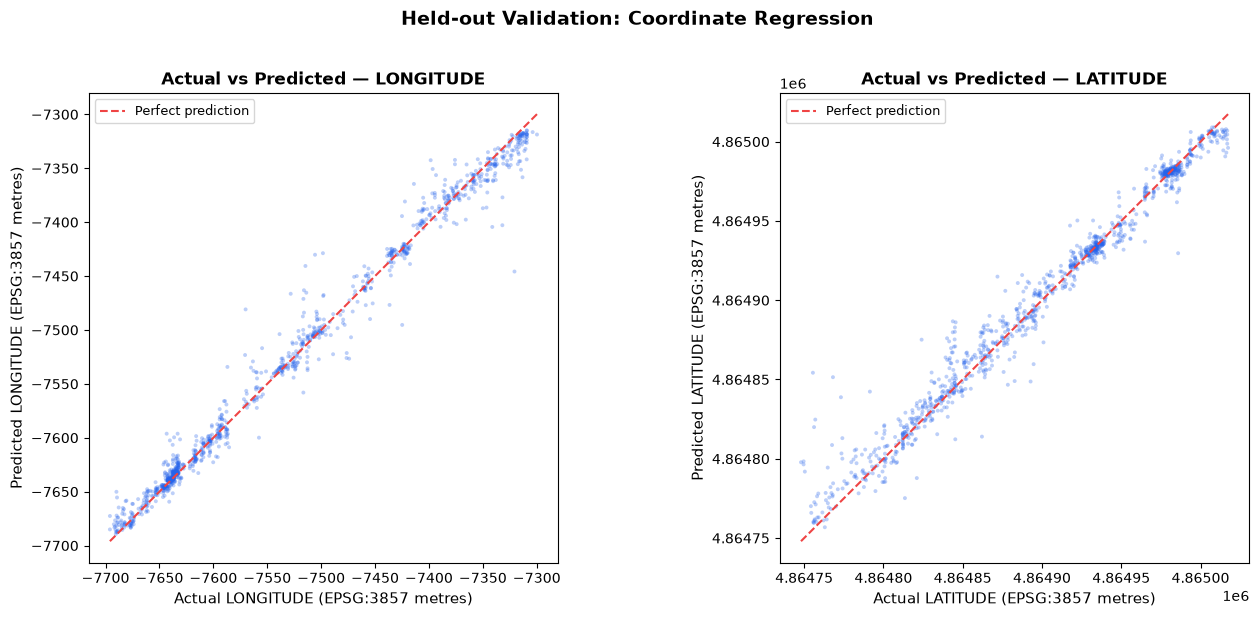

In [11]:
# ── 7a. Actual vs predicted scatter for each coordinate axis ──────────

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax_idx, (col_idx, col_name) in enumerate(zip(range(2), TARGET_COLUMNS)):
    ax = axes[ax_idx]
    actual = y_heldout[:, col_idx]
    predicted = y_heldout_pred[:, col_idx]

    ax.scatter(actual, predicted, alpha=0.3, s=8, color="#2563eb", edgecolors="none")

    # Reference line
    lo = min(actual.min(), predicted.min())
    hi = max(actual.max(), predicted.max())
    ax.plot([lo, hi], [lo, hi], "--", color="#ef4444", linewidth=1.5,
            label="Perfect prediction")

    ax.set_xlabel(f"Actual {col_name} (EPSG:3857 metres)", fontsize=11)
    ax.set_ylabel(f"Predicted {col_name} (EPSG:3857 metres)", fontsize=11)
    ax.set_title(f"Actual vs Predicted — {col_name}", fontsize=12, fontweight="bold")
    ax.legend(fontsize=9)
    ax.set_aspect("equal", adjustable="box")

fig.suptitle("Held-out Validation: Coordinate Regression", fontsize=14, fontweight="bold", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "ml_04_coordinate_actual_vs_predicted.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Coordinate-space error visualisations

These figures use the dataset's two coordinate values directly. Because the
coordinates are interpreted as EPSG:3857 projected metres, they are projected-coordinate views with no basemap or reprojection
applied.

Two plots:
1. **Error scatter.** Actual sample positions coloured by Euclidean prediction error.
2. **Displacement segments.** Lines from actual to predicted positions showing direction and magnitude of each prediction error.


**Cell purpose:** Creates coordinate prediction or error visualizations for held-out rows.


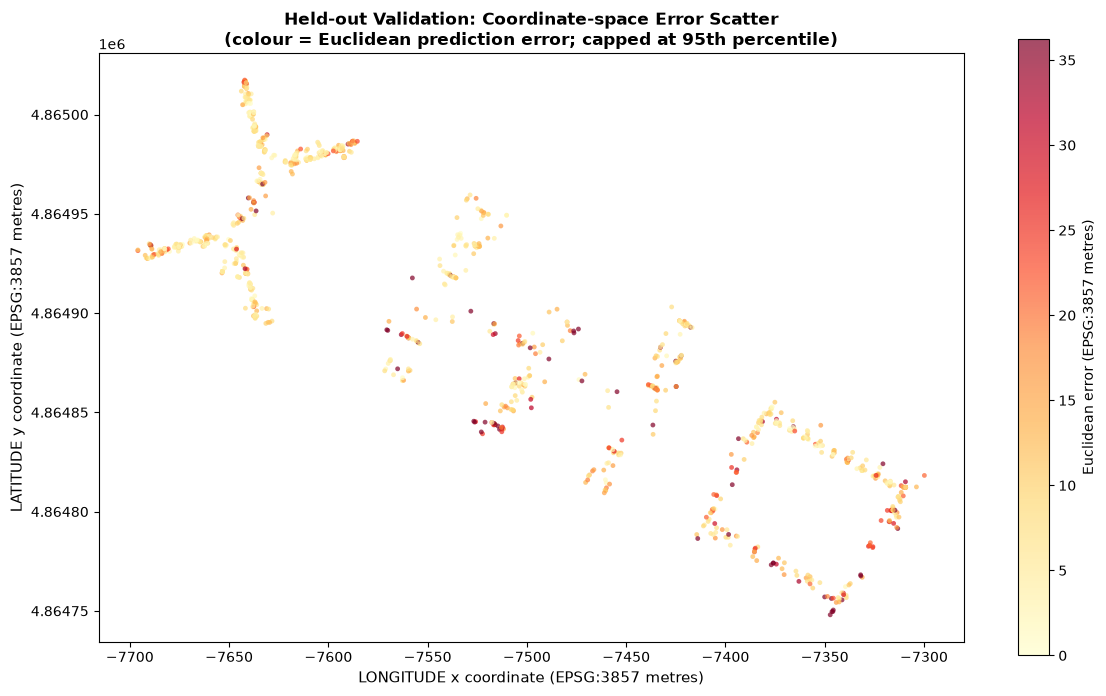

In [12]:
# ── 8a. Coordinate-space error scatter (actual positions coloured by error) ────────

euclidean_errors = np.sqrt(np.sum((y_heldout - y_heldout_pred) ** 2, axis=1))

fig, ax = plt.subplots(figsize=(12, 8))
sc = ax.scatter(
    y_heldout[:, 0],   # LONGITUDE coordinate
    y_heldout[:, 1],   # LATITUDE coordinate
    c=euclidean_errors,
    cmap="YlOrRd",
    s=12,
    alpha=0.7,
    edgecolors="none",
    vmin=0,
    vmax=np.percentile(euclidean_errors, 95),
)
cbar = fig.colorbar(sc, ax=ax, shrink=0.8, label="Euclidean error (EPSG:3857 metres)")
ax.set_xlabel("LONGITUDE x coordinate (EPSG:3857 metres)", fontsize=11)
ax.set_ylabel("LATITUDE y coordinate (EPSG:3857 metres)", fontsize=11)
ax.set_title("Held-out Validation: Coordinate-space Error Scatter\n"
             "(colour = Euclidean prediction error; capped at 95th percentile)",
             fontsize=12, fontweight="bold")
ax.set_aspect("equal", adjustable="box")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "ml_04_coordinate_error_map.png", dpi=160, bbox_inches="tight")
plt.show()

**Cell purpose:** Creates coordinate prediction or error visualizations for held-out rows.


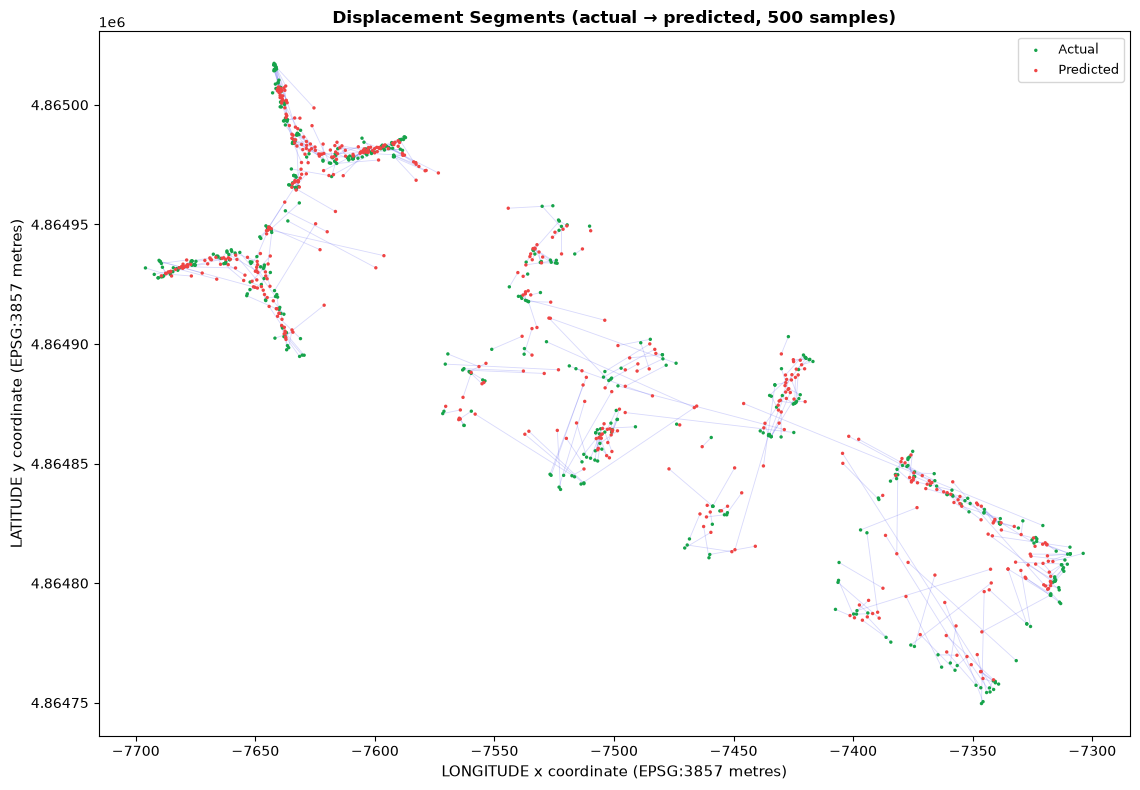

In [13]:
# ── 8b. Displacement segments (actual → predicted) ────────────────────

fig, ax = plt.subplots(figsize=(12, 8))

# Subsample for visual clarity when many points overlap
rng = np.random.RandomState(RANDOM_STATE)
n_show = min(500, len(y_heldout))
idx = rng.choice(len(y_heldout), size=n_show, replace=False)

for i in idx:
    ax.plot(
        [y_heldout[i, 0], y_heldout_pred[i, 0]],
        [y_heldout[i, 1], y_heldout_pred[i, 1]],
        color="#6366f1", alpha=0.25, linewidth=0.6,
    )

ax.scatter(y_heldout[idx, 0], y_heldout[idx, 1], s=6, c="#16a34a",
           label="Actual", zorder=3, edgecolors="none")
ax.scatter(y_heldout_pred[idx, 0], y_heldout_pred[idx, 1], s=6, c="#ef4444",
           label="Predicted", zorder=3, edgecolors="none")

ax.set_xlabel("LONGITUDE x coordinate (EPSG:3857 metres)", fontsize=11)
ax.set_ylabel("LATITUDE y coordinate (EPSG:3857 metres)", fontsize=11)
ax.set_title(f"Displacement Segments (actual → predicted, {n_show} samples)",
             fontsize=12, fontweight="bold")
ax.legend(fontsize=9)
ax.set_aspect("equal", adjustable="box")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "ml_04_coordinate_displacement_segments.png", dpi=160, bbox_inches="tight")
plt.show()

**Cell purpose:** Creates coordinate prediction or error visualizations for held-out rows.


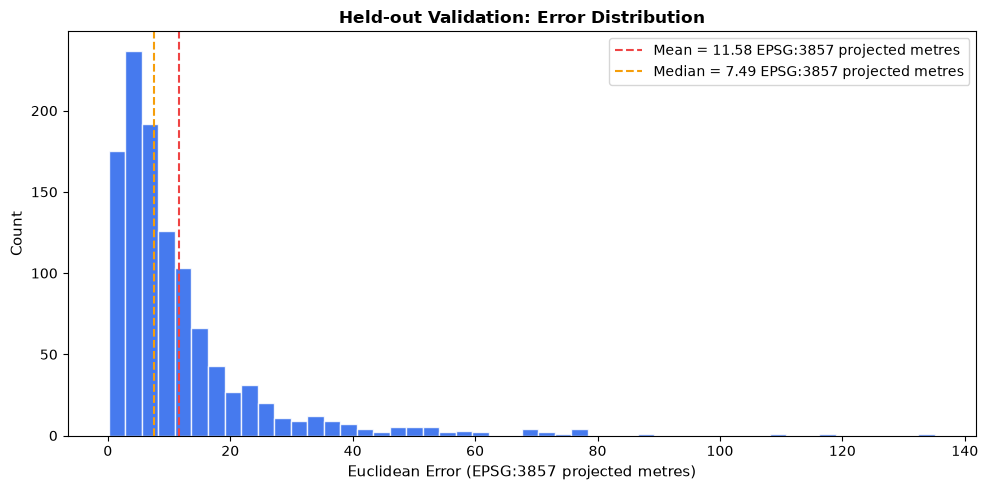

In [14]:
# ── 8c. Error distribution histogram ─────────────────────────────────

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(euclidean_errors, bins=50, color="#2563eb", edgecolor="white",
        alpha=0.85)
ax.axvline(heldout_metrics["mean_euclidean_error"], color="#ef4444",
           linestyle="--", linewidth=1.5,
           label=f"Mean = {heldout_metrics['mean_euclidean_error']:.2f} EPSG:3857 projected metres")
ax.axvline(heldout_metrics["median_euclidean_error"], color="#f59e0b",
           linestyle="--", linewidth=1.5,
           label=f"Median = {heldout_metrics['median_euclidean_error']:.2f} EPSG:3857 projected metres")
ax.set_xlabel("Euclidean Error (EPSG:3857 projected metres)", fontsize=11)
ax.set_ylabel("Count", fontsize=11)
ax.set_title("Held-out Validation: Error Distribution", fontsize=12,
             fontweight="bold")
ax.legend(fontsize=10)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "ml_04_coordinate_error_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

## 10. Export CSV artifacts

All outputs are saved to the existing `data/processed/` directory.

Prediction CSVs include `COORDINATE_CRS` (`EPSG:3857`) and `COORDINATE_UNIT` (`metre`) fields. Metric and tuning CSVs record the same coordinate basis in `coordinate_unit_basis`.

**Cell purpose:** Writes prediction or model metric tables to the processed tables folder.


In [15]:
# ── 9a. Heldout predictions CSV ──────────────────────────────────────

heldout_pred_df = heldout_ids.copy()
heldout_pred_df["LONGITUDE_TRUE"] = y_heldout[:, 0]
heldout_pred_df["LATITUDE_TRUE"]  = y_heldout[:, 1]
heldout_pred_df["LONGITUDE_PRED"] = y_heldout_pred[:, 0]
heldout_pred_df["LATITUDE_PRED"]  = y_heldout_pred[:, 1]
heldout_pred_df["ERROR_LONGITUDE"] = np.abs(y_heldout[:, 0] - y_heldout_pred[:, 0])
heldout_pred_df["ERROR_LATITUDE"]  = np.abs(y_heldout[:, 1] - y_heldout_pred[:, 1])
heldout_pred_df["EUCLIDEAN_ERROR"] = euclidean_errors

heldout_pred_df["COORDINATE_CRS"] = "EPSG:3857"
heldout_pred_df["COORDINATE_UNIT"] = "metre"

heldout_pred_path = TABLES_DIR / "ml_04_coordinate_heldout_predictions.csv"
heldout_pred_df.to_csv(heldout_pred_path, index=False)
print(f"Saved: {heldout_pred_path} ({len(heldout_pred_df)} rows)")
display(heldout_pred_df.head())

Saved: /Users/Krishiv/Desktop/Signal2Space/data/tables/ml_04_coordinate_heldout_predictions.csv (1111 rows)


,ROW_ID,SOURCE_PARTITION,LONGITUDE_TRUE,LATITUDE_TRUE,LONGITUDE_PRED,LATITUDE_PRED,ERROR_LONGITUDE,ERROR_LATITUDE,EUCLIDEAN_ERROR,COORDINATE_CRS,COORDINATE_UNIT
0,0,validationData,-7515.916799,4.864890e+06,-7483.917616,4.864878e+06,31.999183,11.354111,33.953844,EPSG:3857,metre
1,1,validationData,-7383.867221,4.864840e+06,-7397.944833,4.864852e+06,14.077612,12.047136,18.528698,EPSG:3857,metre
2,2,validationData,-7374.302080,4.864847e+06,-7401.830730,4.864861e+06,27.528650,14.864967,31.285681,EPSG:3857,metre
3,3,validationData,-7365.824883,4.864843e+06,-7397.668019,4.864860e+06,31.843136,17.329764,36.253359,EPSG:3857,metre
4,4,validationData,-7641.499303,4.864922e+06,-7647.832575,4.864920e+06,6.333272,2.866717,6.951863,EPSG:3857,metre


**Cell purpose:** Writes prediction or model metric tables to the processed tables folder.


In [16]:
# ── 9b. Internal validation predictions CSV ──────────────────────────

ival_euclidean_errors = np.sqrt(
    np.sum((y_ival - y_ival_pred_final) ** 2, axis=1)
)

ival_pred_df = ival_ids.copy()
ival_pred_df["LONGITUDE_TRUE"] = y_ival[:, 0]
ival_pred_df["LATITUDE_TRUE"]  = y_ival[:, 1]
ival_pred_df["LONGITUDE_PRED"] = y_ival_pred_final[:, 0]
ival_pred_df["LATITUDE_PRED"]  = y_ival_pred_final[:, 1]
ival_pred_df["ERROR_LONGITUDE"] = np.abs(y_ival[:, 0] - y_ival_pred_final[:, 0])
ival_pred_df["ERROR_LATITUDE"]  = np.abs(y_ival[:, 1] - y_ival_pred_final[:, 1])
ival_pred_df["EUCLIDEAN_ERROR"] = ival_euclidean_errors

ival_pred_df["COORDINATE_CRS"] = "EPSG:3857"
ival_pred_df["COORDINATE_UNIT"] = "metre"

ival_pred_path = TABLES_DIR / "ml_04_coordinate_internal_validation_predictions.csv"
ival_pred_df.to_csv(ival_pred_path, index=False)
print(f"Saved: {ival_pred_path} ({len(ival_pred_df)} rows)")

Saved: /Users/Krishiv/Desktop/Signal2Space/data/tables/ml_04_coordinate_internal_validation_predictions.csv (3852 rows)


**Cell purpose:** Initializes rows for baseline, tuned, and held-out coordinate metrics.


In [17]:
# ── 9c. Metrics CSV ──────────────────────────────────────────────────

metrics_rows = []

# Baseline on internal validation
metrics_rows.append({
    "split": "internal_validation",
    "model_family": "RandomForestRegressor",
    "coordinate_unit_basis": "EPSG:3857 projected metres (Web/Pseudo-Mercator)",
    "model_config": "baseline",
    "n_estimators": 100,
    "max_depth": "",
    "min_samples_leaf": 1,
    "max_features": 1.0,
    "mae_LONGITUDE_coordinate_units": baseline_metrics["mae_LONGITUDE"],
    "mae_LATITUDE_coordinate_units": baseline_metrics["mae_LATITUDE"],
    "mean_euclidean_error_coordinate_units": baseline_metrics["mean_euclidean_error"],
    "median_euclidean_error_coordinate_units": baseline_metrics["median_euclidean_error"],
    "n_rows": len(y_ival),
})



**Cell purpose:** Adds baseline and tuned internal-validation metric records.


In [18]:
# Tuned on internal validation
metrics_rows.append({
    "split": "internal_validation",
    "model_family": "RandomForestRegressor",
    "coordinate_unit_basis": "EPSG:3857 projected metres (Web/Pseudo-Mercator)",
    "model_config": "tuned",
    "n_estimators": BEST_PARAMS["n_estimators"],
    "max_depth": BEST_PARAMS["max_depth"] if BEST_PARAMS["max_depth"] is not None else "",
    "min_samples_leaf": BEST_PARAMS["min_samples_leaf"],
    "max_features": BEST_PARAMS["max_features"],
    "mae_LONGITUDE_coordinate_units": ival_metrics["mae_LONGITUDE"],
    "mae_LATITUDE_coordinate_units": ival_metrics["mae_LATITUDE"],
    "mean_euclidean_error_coordinate_units": ival_metrics["mean_euclidean_error"],
    "median_euclidean_error_coordinate_units": ival_metrics["median_euclidean_error"],
    "n_rows": len(y_ival),
})



**Cell purpose:** Adds the frozen model’s held-out metric record.


In [19]:
# Tuned on held-out validation
metrics_rows.append({
    "split": "heldout_validation",
    "model_family": "RandomForestRegressor",
    "coordinate_unit_basis": "EPSG:3857 projected metres (Web/Pseudo-Mercator)",
    "model_config": "tuned",
    "n_estimators": BEST_PARAMS["n_estimators"],
    "max_depth": BEST_PARAMS["max_depth"] if BEST_PARAMS["max_depth"] is not None else "",
    "min_samples_leaf": BEST_PARAMS["min_samples_leaf"],
    "max_features": BEST_PARAMS["max_features"],
    "mae_LONGITUDE_coordinate_units": heldout_metrics["mae_LONGITUDE"],
    "mae_LATITUDE_coordinate_units": heldout_metrics["mae_LATITUDE"],
    "mean_euclidean_error_coordinate_units": heldout_metrics["mean_euclidean_error"],
    "median_euclidean_error_coordinate_units": heldout_metrics["median_euclidean_error"],
    "n_rows": len(y_heldout),
})



**Cell purpose:** Writes the coordinate metric table.


In [20]:
metrics_df = pd.DataFrame(metrics_rows)
metrics_path = TABLES_DIR / "ml_04_coordinate_metrics.csv"
metrics_df.to_csv(metrics_path, index=False)
print(f"Saved: {metrics_path}")
display(metrics_df)

Saved: /Users/Krishiv/Desktop/Signal2Space/data/tables/ml_04_coordinate_metrics.csv


,split,model_family,coordinate_unit_basis,model_config,n_estimators,max_depth,min_samples_leaf,max_features,mae_LONGITUDE_coordinate_units,mae_LATITUDE_coordinate_units,mean_euclidean_error_coordinate_units,median_euclidean_error_coordinate_units,n_rows
0,internal_validation,RandomForestRegressor,EPSG:3857 projected metres (Web/Pseudo-Mercator),baseline,100,,1,1.0,6.416407,5.359463,9.256109,6.508299,3852
1,internal_validation,RandomForestRegressor,EPSG:3857 projected metres (Web/Pseudo-Mercator),tuned,150,,1,0.5,5.914234,5.060706,8.578616,6.306672,3852
2,heldout_validation,RandomForestRegressor,EPSG:3857 projected metres (Web/Pseudo-Mercator),tuned,150,,1,0.5,8.096594,6.806426,11.583571,7.488385,1111


**Cell purpose:** Exports the tuning results with the coordinate unit basis.


In [21]:
# ── 9d. Tuning results CSV ───────────────────────────────────────────

tuning_export_df = tuning_df.copy()
tuning_export_df.insert(0, "model_family", "RandomForestRegressor")
tuning_export_df.insert(1, "coordinate_unit_basis", "EPSG:3857 projected metres (Web/Pseudo-Mercator)")
# Rename metrics for clarity
tuning_export_df = tuning_export_df.rename(columns={
    "mae_LONGITUDE": "mae_LONGITUDE_coordinate_units",
    "mae_LATITUDE": "mae_LATITUDE_coordinate_units",
    "mean_euclidean_error": "mean_euclidean_error_coordinate_units",
    "median_euclidean_error": "median_euclidean_error_coordinate_units",
    "p75_euclidean_error": "p75_euclidean_error_coordinate_units",
    "p95_euclidean_error": "p95_euclidean_error_coordinate_units",
})
tuning_path = TABLES_DIR / "ml_04_coordinate_tuning_results.csv"
tuning_export_df.to_csv(tuning_path, index=False)
print(f"Saved: {tuning_path} ({len(tuning_export_df)} rows)")

Saved: /Users/Krishiv/Desktop/Signal2Space/data/tables/ml_04_coordinate_tuning_results.csv (10 rows)


## 11. Verification and summary

**Cell purpose:** Reloads outputs and verifies prediction alignment and upstream artifact preservation.


In [22]:
# ── 10. Post-run verification ─────────────────────────────────────────

# Verify CSV artifacts exist and reload cleanly
for path in [heldout_pred_path, ival_pred_path, metrics_path, tuning_path]:
    assert path.is_file(), f"Missing artifact: {path}"
    reloaded = pd.read_csv(path)
    print(f"  ✓ {path.name}: {reloaded.shape[0]} rows, {reloaded.shape[1]} cols")

# Verify heldout predictions alignment
hp = pd.read_csv(heldout_pred_path)
assert len(hp) == len(heldout_df), \
    f"Row count mismatch: predictions {len(hp)} vs heldout {len(heldout_df)}"
assert (hp["ROW_ID"].values == heldout_df["ROW_ID"].values).all(), \
    "ROW_ID alignment mismatch"
assert np.allclose(hp["LONGITUDE_TRUE"].values, y_heldout[:, 0]), \
    "LONGITUDE_TRUE mismatch"
assert np.allclose(hp["LATITUDE_TRUE"].values, y_heldout[:, 1]), \
    "LATITUDE_TRUE mismatch"
print("  ✓ Heldout predictions aligned with source data")

# Verify ival predictions alignment
ip = pd.read_csv(ival_pred_path)
assert len(ip) == len(ival_df), \
    f"Row count mismatch: predictions {len(ip)} vs ival {len(ival_df)}"
print("  ✓ Internal validation predictions aligned")

# Verify no preprocessing or classification artifacts were overwritten
for existing in ["aml_internal_train_features.csv",
                 "aml_internal_validation_features.csv",
                 "aml_heldout_validation_features.csv"]:
    assert (PROCESSED_DIR / existing).is_file(), f"Missing processed data: {existing}"
for existing in ["ml_02_building_metrics.csv",
                 "ml_02_building_heldout_predictions.csv",
                 "ml_02_building_heldout_confusion_matrix.csv",
                 "ml_02_building_internal_validation_predictions.csv",
                 "ml_03_floor_metrics.csv",
                 "ml_03_floor_heldout_predictions.csv",
                 "ml_03_floor_heldout_confusion_matrix.csv",
                 "ml_03_floor_internal_validation_predictions.csv"]:
    assert (TABLES_DIR / existing).is_file(), f"Missing model result: {existing}"
print("  ✓ All preprocessing and classification artifacts are intact")

  ✓ ml_04_coordinate_heldout_predictions.csv: 1111 rows, 11 cols
  ✓ ml_04_coordinate_internal_validation_predictions.csv: 3852 rows, 11 cols
  ✓ ml_04_coordinate_metrics.csv: 3 rows, 13 cols
  ✓ ml_04_coordinate_tuning_results.csv: 10 rows, 12 cols
  ✓ Heldout predictions aligned with source data
  ✓ Internal validation predictions aligned
  ✓ All preprocessing and classification artifacts are intact


## Conclusion

This notebook fits the coordinate regressor and evaluates it using the shared feature and split definitions. Coordinate MAE and distance errors use the documented EPSG:3857 projected coordinate units; they are not scale-corrected ground distances. The supplied split may include repeated fingerprints and coordinate values, so scores do not establish performance on unseen positions.

## Next Steps

Use the coordinate prediction and metric CSVs in the integrated AML evaluation. Keep the coordinate reference and unit caveat with reported results, and interpret coordinate error alongside building and floor outcomes.